# 04 — XGBoost Regressor | HRI Score

**J26-IT-359, Component 04.** Same frozen training/validation/test splits and 9 environmental predictors as Models 01–03. This models a **constructed same-year HRI score**, not future habitat degradation. Do not tune on the final test set.


**Experiment 2:** uses only nine climate/terrain features. Missing flags and observation context are excluded. Rows with missing/nonfinite selected inputs or targets are dropped within each frozen split. Previously imputed values in the supplied CSVs remain available. Outputs are saved separately under `artifacts/hri/experiment_2/`.


## 1 — Dependencies

In [1]:
%pip install pandas numpy scikit-learn matplotlib joblib xgboost



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2 — Imports and paths
The paths below find `components/habitat_risk` from the repository, component, notebook, or `Model_Training` working directory and load the frozen normalized splits from `data/splits/hri/model_v1/`.

In [2]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Find components/habitat_risk without depending on the Jupyter working directory.
cwd = Path.cwd().resolve()
search_roots = [cwd, *cwd.parents]
PROJECT_ROOT = next(
    (p for p in search_roots if (p / 'data/splits/hri/model_v1/train.csv').is_file()),
    None,
)
if PROJECT_ROOT is None:
    PROJECT_ROOT = next(
        (p / 'components/habitat_risk' for p in search_roots
         if (p / 'components/habitat_risk/data/splits/hri/model_v1/train.csv').is_file()),
        None,
    )
if PROJECT_ROOT is None:
    raise RuntimeError(f'Could not find components/habitat_risk from: {cwd}')

DATA_DIR = PROJECT_ROOT / 'data/splits/hri/model_v1'
TRAIN_FILE = DATA_DIR / 'train.csv'
VAL_FILE = DATA_DIR / 'validation.csv'
TEST_FILE = DATA_DIR / 'test.csv'
OUTPUT_DIR = PROJECT_ROOT / 'artifacts/hri/experiment_2/xgboost'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Training file:', TRAIN_FILE)
print('Validation exists:', VAL_FILE.exists(), 'Test exists:', TEST_FILE.exists())

Training file: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/splits/hri/model_v1/train.csv
Validation exists: True Test exists: True


## 3 — Load frozen data and audit schema

In [3]:
if not TRAIN_FILE.exists():
    raise FileNotFoundError(f'Cannot find training file: {TRAIN_FILE}. Update DATA_DIR.')
train = pd.read_csv(TRAIN_FILE)
val = pd.read_csv(VAL_FILE) if VAL_FILE.exists() else None
test = pd.read_csv(TEST_FILE) if TEST_FILE.exists() else None
for name, frame in [('train', train), ('validation', val), ('test', test)]:
    if frame is not None:
        print(name, frame.shape, 'missing cells:', int(frame.isna().sum().sum()))
        if 'dataset_split' in frame:
            print('Saved split labels:', frame['dataset_split'].value_counts(dropna=False).to_dict())
display(train.head(3))

train (24752, 33) missing cells: 158548
Saved split labels: {'train': 24752}
validation (5306, 33) missing cells: 33746
Saved split labels: {'validation': 5306}
test (5292, 33) missing cells: 32846
Saved split labels: {'test': 5292}


,cell_id,reference_year,dataset_split,climate__annual_mean_temperature_c,climate__annual_precipitation_mm,climate__temperature_c_anomaly,climate__temperature_c_trailing5_slope_per_year,climate__precipitation_mm_anomaly,climate__precipitation_mm_trailing5_slope_per_year,terrain__mean_elevation_m,...,quantile_risk_class,context__observed_checklist_locations,context__sampled_ndvi_mean,context__ndvi_valid_event_count,context__sampled_elevation_mean_m,context__survey_duration_mean_minutes,context__survey_distance_mean_km,context__sampled_land_cover_mode,context__bird_evidence_available,context__sampled_ndvi_missing
0,lka_laea_5000m_-10_-1,2010,train,0.776597,0.282989,0.480505,0.429949,0.527164,0.524089,0.047672,...,High,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1
1,lka_laea_5000m_-10_-12,2010,train,0.717720,0.404530,0.480505,0.429949,0.527164,0.524089,0.066682,...,Low,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1
2,lka_laea_5000m_-10_-13,2010,train,0.702525,0.424296,0.480505,0.429949,0.527164,0.524089,0.063003,...,Low,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1


## 4 — Define target and predictors
`cell_id` and `reference_year` are retained for audit but not used as predictors in this baseline. Exclude both risk-class labels and the target from X. Predictor names are explicit, so an unexpected column cannot silently leak into the model.

In [4]:
TARGET = 'hri_score_0_100'
FEATURES = [
 'climate__annual_mean_temperature_c',
 'climate__annual_precipitation_mm',
 'climate__temperature_c_anomaly',
 'climate__temperature_c_trailing5_slope_per_year',
 'climate__precipitation_mm_anomaly',
 'climate__precipitation_mm_trailing5_slope_per_year',
 'terrain__mean_elevation_m',
 'terrain__elevation_sd_m',
 'terrain__mean_slope_degrees',
]
# Experiment 2: select nine environmental inputs; ignore context/flag columns.
feature_cols = FEATURES
rows_removed = {}
def clean_selected_rows(name, frame):
    if frame is None:
        return None
    required = FEATURES + [TARGET]
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f'{name} is missing required columns: {missing}')
    result = frame.copy()
    result[required] = result[required].apply(pd.to_numeric, errors='coerce')
    result[required] = result[required].replace([np.inf, -np.inf], np.nan)
    result = result.dropna(subset=required).copy()
    rows_removed[name] = len(frame) - len(result)
    if result.empty:
        raise ValueError(f'{name} has no valid rows after cleaning')
    return result
train = clean_selected_rows('train', train)
val = clean_selected_rows('validation', val)
test = clean_selected_rows('test', test)
print('Rows removed for missing selected features/target:', rows_removed)

for name, frame in [('train', train), ('validation', val), ('test', test)]:
    if frame is None: continue
    missing = sorted(set(FEATURES + [TARGET]) - set(frame.columns))
    if missing: raise ValueError(f'{name} is missing columns: {missing}')
    if frame[TARGET].isna().any(): raise ValueError(f'{name} has missing targets')
    if 'dataset_split' in frame and not frame['dataset_split'].eq(name).all():
        raise ValueError(f'{name} has inconsistent dataset_split labels')
    if frame.duplicated(['cell_id','reference_year']).any():
        raise ValueError(f'{name} has duplicate cell_id/reference_year keys')

# Check for identical cell-year records appearing in multiple files.
sets = {name: set(zip(frame.cell_id, frame.reference_year)) for name, frame in [('train',train),('validation',val),('test',test)] if frame is not None}
from itertools import combinations
for a, b in combinations(sets, 2):
    overlap = sets[a] & sets[b]
    if overlap: raise ValueError(f'{len(overlap)} overlapping keys between {a} and {b}')
cell_sets = {name: set(frame.cell_id) for name, frame in [('train',train),('validation',val),('test',test)] if frame is not None}
for a, b in combinations(cell_sets, 2):
    overlap = cell_sets[a] & cell_sets[b]
    if overlap: raise ValueError(f'{len(overlap)} spatial cells overlap between {a} and {b}')

X_train, y_train = train[FEATURES], train[TARGET]
print('Features:', len(FEATURES), 'Train samples:', len(train))
print('Target summary:'); display(y_train.describe())
if val is not None:
    X_val, y_val = val[feature_cols], val[TARGET]


Rows removed for missing selected features/target: {'train': 0, 'validation': 0, 'test': 0}
Features: 9 Train samples: 24752
Target summary:


count    24752.000000
mean        37.042325
std         14.326639
min          0.793036
25%         27.360073
50%         35.769426
75%         44.626012
max         93.502631
Name: hri_score_0_100, dtype: float64

## 5 — Fit XGBoost on training data only

Fixed initial hyperparameters, not tuned. Keep identical predictors and frozen splits for fair comparisons.


In [5]:
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', XGBRegressor(n_estimators=350,max_depth=4,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,reg_lambda=5,objective="reg:squarederror",random_state=42,n_jobs=-1))
])
start = time.perf_counter()
model.fit(X_train, y_train)
train_seconds = time.perf_counter() - start
print(f'XGBoost trained in {train_seconds:.2f} seconds')


XGBoost trained in 0.44 seconds


## 6 — Training diagnostics (not generalization performance)

In [6]:
def score_split(name, frame):
    y_true = frame[TARGET].to_numpy()
    predictions = model.predict(frame[FEATURES])
    metrics = {
        'model': 'XGBoost', 'split': name, 'n_rows': len(frame),
        'MAE': float(mean_absolute_error(y_true, predictions)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, predictions))),
        'R2': float(r2_score(y_true, predictions)),
        'train_seconds': float(train_seconds)
    }
    return metrics, predictions

train_metrics, train_pred = score_split('train', train)
display(pd.DataFrame([train_metrics]))
print('TRAIN metrics only: do not present these as held-out performance.')

,model,split,n_rows,MAE,RMSE,R2,train_seconds
0,XGBoost,train,24752,6.864422,9.504522,0.559861,0.442386


TRAIN metrics only: do not present these as held-out performance.


## 7 — Validation using the frozen `validation.csv`

In [7]:
metrics_rows = [train_metrics]
if val is None:
    print('No validation.csv found. Validation is SKIPPED — do not use training metrics to select the best model.')
else:
    val_metrics, val_pred = score_split('validation', val)
    metrics_rows.append(val_metrics)
    display(pd.DataFrame([val_metrics]))

,model,split,n_rows,MAE,RMSE,R2,train_seconds
0,XGBoost,validation,5306,7.89067,10.885319,0.349848,0.442386


## 8 — Holdout test: only when the original frozen `test.csv` is supplied
**Run this cell once after your modeling choices are finalized.** Repeatedly consulting the test set to choose features/hyperparameters causes test-set leakage.

In [8]:
RUN_FINAL_TEST = False  # Change to True only after model selection is finalized.
if not RUN_FINAL_TEST:
    print('Final test is LOCKED. Set RUN_FINAL_TEST=True only when ready for final reporting.')
elif test is None:
    print('No test.csv found. Test metrics cannot be computed.')
else:
    test_metrics, test_pred = score_split('test', test)
    metrics_rows.append(test_metrics)
    display(pd.DataFrame([test_metrics]))

Final test is LOCKED. Set RUN_FINAL_TEST=True only when ready for final reporting.


## 9 — Plots: observed vs predicted and residuals
Uses validation if available, otherwise training. Training plots are diagnostic only.

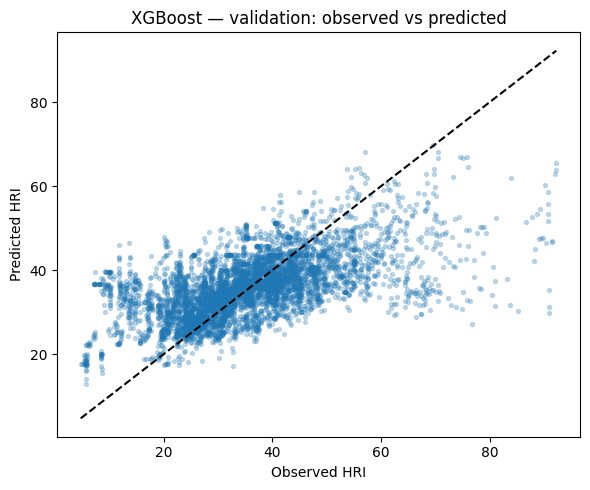

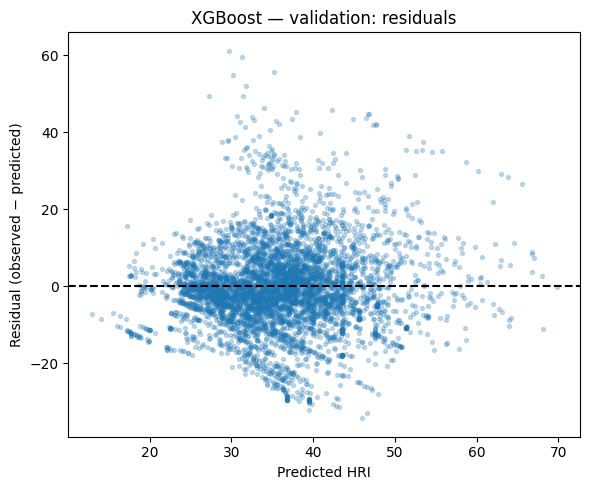

In [9]:
plot_frame = val if val is not None else train
plot_name = 'validation' if val is not None else 'train'
actual = plot_frame[TARGET].to_numpy()
pred = model.predict(plot_frame[FEATURES])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(actual, pred, alpha=0.25, s=8)
lo, hi = min(actual.min(), pred.min()), max(actual.max(), pred.max())
ax.plot([lo, hi], [lo, hi], 'k--')
ax.set(xlabel='Observed HRI', ylabel='Predicted HRI', title=f'XGBoost — {plot_name}: observed vs predicted')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / f'{plot_name}_actual_vs_predicted.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(pred, actual - pred, alpha=0.25, s=8)
ax.axhline(0, color='black', linestyle='--')
ax.set(xlabel='Predicted HRI', ylabel='Residual (observed − predicted)', title=f'XGBoost — {plot_name}: residuals')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / f'{plot_name}_residuals.png', dpi=180)
plt.show()

## 10 — XGBoost feature importance

Built-in importance is descriptive, not causal evidence.


,feature,importance
8,terrain__mean_slope_degrees,0.282535
6,terrain__mean_elevation_m,0.135113
7,terrain__elevation_sd_m,0.117047
0,climate__annual_mean_temperature_c,0.114602
2,climate__temperature_c_anomaly,0.082586
1,climate__annual_precipitation_mm,0.076196
4,climate__precipitation_mm_anomaly,0.071799
5,climate__precipitation_mm_trailing5_slope_per_...,0.063251
3,climate__temperature_c_trailing5_slope_per_year,0.056871


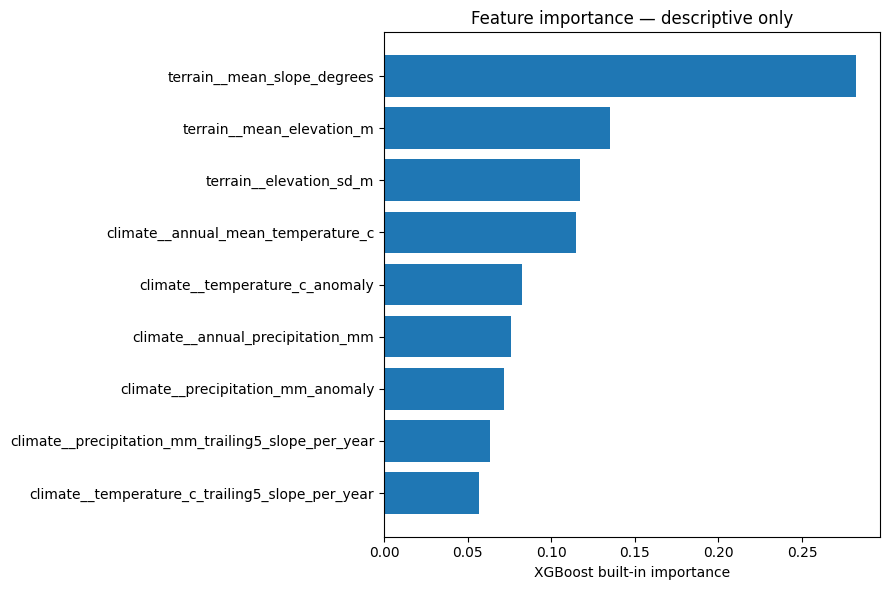

In [10]:
importances = pd.DataFrame({
    'feature': FEATURES,
    'importance': model.named_steps['regressor'].feature_importances_
}).sort_values('importance', ascending=False)
display(importances)
importances.to_csv(OUTPUT_DIR / 'feature_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importances['feature'].iloc[::-1], importances['importance'].iloc[::-1])
ax.set_xlabel('XGBoost built-in importance')
ax.set_title('Feature importance — descriptive only')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'feature_importance.png', dpi=160)
plt.show()


## 11 — Error by fixed HRI risk band (validation)

Use the exact risk class already stored in the validation CSV rather than guessing thresholds. Negative mean signed error means underprediction.

In [11]:
if val is None:
    print('Risk-band validation skipped: validation.csv is unavailable.')
elif 'fixed_risk_class' not in val.columns:
    print('Risk-band validation skipped: fixed_risk_class column unavailable.')
else:
    band = pd.DataFrame({
        'risk_class': val['fixed_risk_class'].to_numpy(),
        'actual': val[TARGET].to_numpy(),
        'predicted': model.predict(val[FEATURES])
    })
    band['absolute_error'] = (band['predicted'] - band['actual']).abs()
    band['signed_error'] = band['predicted'] - band['actual']
    band_summary = band.groupby('risk_class', dropna=False).agg(
        samples=('actual', 'size'), MAE=('absolute_error', 'mean'),
        mean_signed_error=('signed_error', 'mean'),
        mean_actual=('actual', 'mean'), mean_predicted=('predicted', 'mean')
    ).reset_index()
    display(band_summary.round(3))
    band_summary.to_csv(OUTPUT_DIR / 'validation_risk_band_errors.csv', index=False)

,risk_class,samples,MAE,mean_signed_error,mean_actual,mean_predicted
0,High,146,29.318,-29.315,74.761,45.445999
1,Low,2434,7.827,6.959,24.522,31.481001
2,Moderate,2726,6.800,-4.060,43.495,39.435001


## 12 — Target distribution: training versus validation

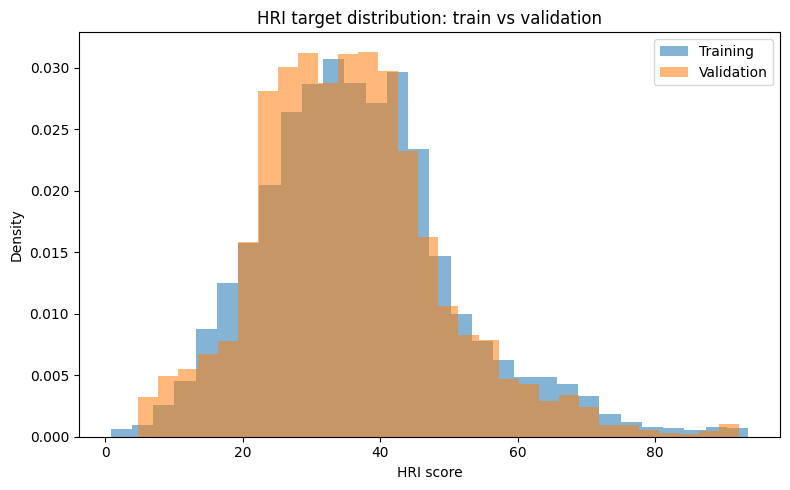

In [12]:
if val is None:
    print('Validation distribution plot skipped: validation.csv unavailable.')
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(train[TARGET], bins=30, density=True, alpha=0.55, label='Training')
    ax.hist(val[TARGET], bins=30, density=True, alpha=0.55, label='Validation')
    ax.set(xlabel='HRI score', ylabel='Density', title='HRI target distribution: train vs validation')
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'target_distribution.png', dpi=180)
    plt.show()

## 13 — Save predictions, metrics, and fitted pipeline

In [13]:
pd.DataFrame(metrics_rows).to_csv(OUTPUT_DIR / 'metrics.csv', index=False)
for name, frame in [('train',train),('validation',val),('test',test if RUN_FINAL_TEST else None)]:
    if frame is None: continue
    export = frame[['cell_id','reference_year',TARGET]].copy()
    export['prediction'] = model.predict(frame[FEATURES])
    export['residual'] = export[TARGET] - export['prediction']
    export.to_csv(OUTPUT_DIR / f'{name}_predictions.csv', index=False)
joblib.dump(model, OUTPUT_DIR / 'xgboost.joblib')
(OUTPUT_DIR / 'experiment_metadata.json').write_text(json.dumps({
    'experiment': 'experiment_2_nine_environmental_features',
    'rows_removed': rows_removed,
    'model_parameters': {k: str(v) for k, v in model.named_steps['regressor'].get_params().items()},
    'target': TARGET, 'features': FEATURES,
    'train_rows': len(train), 'validation_rows': None if val is None else len(val),
    'test_rows': None if test is None else len(test),
    'limitation': 'Not a forecast; HRI is a constructed index and may share inputs with predictors.'
}, indent=2))
print('Saved outputs to:', OUTPUT_DIR)
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved outputs to: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/artifacts/hri/experiment_2/xgboost
['experiment_metadata.json', 'feature_importance.csv', 'feature_importance.png', 'metrics.csv', 'target_distribution.png', 'train_predictions.csv', 'validation_actual_vs_predicted.png', 'validation_predictions.csv', 'validation_residuals.png', 'validation_risk_band_errors.csv', 'xgboost.joblib']


## 14 — Reporting

- **Model:** XGBoost regression, fixed initial settings.
- **Target:** same-year constructed HRI (0–100), not future degradation.
- **Selection:** compare validation MAE/RMSE/R² using identical 9 environmental predictors and saved splits.
- **Final test:** leave locked until model selection is complete.
- **Limitations:** important forest-risk inputs may be absent; this is formula approximation, not a forecast.
